# Caso 2 · Prototipo de priorización de renovaciones

Con los mismos 5 gestores, organizar la cola para que el primer contacto caiga **8–14 días** antes del vencimiento y cada llamada vaya donde más comisión recupera. Se aplica a los 13 meses de datos como si hubiera estado vigente.

**Tres reglas**
1. **Enrutar por canal:** domiciliadas, financiadas y flotas a canal automático; teléfonos inválidos a corrección de datos; a la cola solo el pago manual de individuales y pymes.
2. **Abrir cada expediente 14 días antes** del vencimiento, no 3.
3. **Ordenar por fecha límite y valor** (comisión × mejora esperada).

## 1. Supuestos
Decisiones que condicionan los resultados de este notebook y por qué se tomaron. En el texto y en el código se citan por su código.

| Código | Supuesto | Por qué | Dónde se aplica |
|---|---|---|---|
| **S2.10** | Días hábiles de lunes a viernes, sin feriados (`pd.bdate_range`). | Es el horario de la hoja *Equipo*. La bitácora registra llamadas en feriados, así que no se descuentan; el efecto es ~3.5 % de capacidad. | §4 |
| **S2.11** | Capacidad = 50 llamadas por gestor y día hábil; con 5 gestores, 250 al día (`daily_call_target`, `AGENTES`). | Es la meta de la hoja *Equipo* y los gestores la cumplen desde diciembre (~52 llamadas al día). | §4 |
| **S2.13** | Tramos de anticipación: después del vencimiento, 0–3, 4–7, 8–14, 15–20, 21–25 y 26–30 días (`LEAD_TIME_BINS`). | Separan el estándar de 20 días, la ventana de 8–14 días que más renueva y el contacto de último momento (≤ 3 días). | `00_limpieza` §4.4 |
| **S2.14** | Pago distinto de *Manual* o segmento *Flota corporativa* → canal automático (WhatsApp/correo, tasa esperada 90 %); teléfono inválido → corrección de datos; el resto → cola telefónica (`AUTOMATICO`). | Domiciliadas, financiadas y flotas renuevan al 87–95 % sin importar cuándo se llame: llamarlas no mejora la tasa y consume ~1,100 llamadas al mes. | §2 |
| **S2.15** | Prioridad = comisión potencial × **mejora esperada**; mejora = tasa del segmento en 8–14 días menos la del tramo 0–3 (`VENTANA`). | Ordenar solo por comisión mandaría llamadas a pólizas que renuevan igual; la mejora esperada mide cuánto cambia la renovación si se llama a tiempo. | §3 |
| **S2.16** | Simulación: cada expediente entra 14 días antes del vencimiento (`APERTURA_DIAS`), con fecha límite a 8 (`LIMITE_DIAS`) y 7 días de gracia (`GRACIA_DIAS`); cada póliza consume las llamadas que consumió en la realidad, una por día; el canal automático no devuelve pólizas a la cola. | 14 y 8 días delimitan la ventana que más renueva, y usar los seguimientos reales evita inventar la carga. Es una simplificación optimista: por eso el impacto se da como rango. | §4 |

In [1]:
from pathlib import Path
from statistics import NormalDist
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve().parents[1]  # el notebook corre desde notebooks/caso2/
PROCESSED = ROOT / "data" / "processed" / "caso2_limpio.pkl"
OUTPUTS = ROOT / "outputs"
assert PROCESSED.is_file(), f"No existe {PROCESSED}: ejecuta primero 00_limpieza.ipynb"
d = SimpleNamespace(**pd.read_pickle(PROCESSED))
ren, log = d.renewals.copy(), d.calls
STAFFING_CHANGE_DATE = d.params["staffing_change_date"]
DAILY_CALL_TARGET = d.params["daily_call_target"]
LEAD_LABELS = d.lead_time_labels
LEAD_BINS = d.lead_time_bins  # mismos tramos que 00_limpieza (S2.13 · ver 00_limpieza §3)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update(
    {
        "figure.figsize": (11, 4.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
    }
)

# Parámetros del prototipo (supuestos S2.14–S2.16, ver §1)
AGENTES = 5
CAPACIDAD_DIARIA = AGENTES * DAILY_CALL_TARGET  # llamadas por día hábil
APERTURA_DIAS = 14  # el expediente entra a la cola 14 días antes del vencimiento
LIMITE_DIAS = 8  # fecha límite para el primer contacto: 8 días antes (fin de la ventana 8-14)
VENTANA = ["8-14"]  # tramo objetivo
GRACIA_DIAS = 7  # hasta cuántos días después del vencimiento se sigue intentando el primer contacto
AUTOMATICO = ren["Forma de pago"].ne("Manual") | ren["Segmento"].eq("Flota corporativa")

## 2. Enrutamiento por canal
Cada póliza se asigna a un canal antes de gastar una llamada.

*Supuesto S2.14 (ver §1).*

In [2]:
ren["canal"] = np.select(
    [~ren["valid_phone"], AUTOMATICO],
    ["Corrección de datos (teléfono inválido)", "Canal automático (WhatsApp / correo)"],
    "Cola telefónica",
)
orden_canal = [
    "Cola telefónica",
    "Canal automático (WhatsApp / correo)",
    "Corrección de datos (teléfono inválido)",
]


def resumen_canales(df):
    t = df.groupby("canal").agg(
        polizas=("Póliza", "size"),
        comision_potencial=("potential_commission", "sum"),
        tasa_renovacion=("renewed", "mean"),
        llamadas_historicas=("calls_logged", "sum"),
    )
    t["% pólizas"] = t["polizas"] / t["polizas"].sum()
    t["% comisión"] = t["comision_potencial"] / t["comision_potencial"].sum()
    t["% llamadas"] = t["llamadas_historicas"] / t["llamadas_historicas"].sum()
    return t.reindex(orden_canal)


fmt_canal = {
    "comision_potencial": "USD {:,.0f}",
    "tasa_renovacion": "{:.1%}",
    "% pólizas": "{:.0%}",
    "% comisión": "{:.0%}",
    "% llamadas": "{:.0%}",
    "llamadas_historicas": "{:,.0f}",
}
display(Markdown("**Toda la cartera (13 meses)**"))
display(resumen_canales(ren).style.format(fmt_canal))

r5 = ren[ren["active_agents"] == AGENTES]
meses_5 = r5["expiry_month"].nunique()
t5 = resumen_canales(r5)
display(Markdown(f"**Periodo de 5 gestores ({meses_5} meses)**"))
display(t5.style.format(fmt_canal))
liberadas = t5.loc[t5.index != "Cola telefónica", "llamadas_historicas"].sum() / meses_5
print(
    f"Llamadas al mes que salen de la cola telefónica: {liberadas:,.0f} de {t5['llamadas_historicas'].sum() / meses_5:,.0f} "
    f"({liberadas / (t5['llamadas_historicas'].sum() / meses_5):.0%}); el déficit de capacidad estimado en 01_eda §7 era de ~6 %."
)

**Toda la cartera (13 meses)**

,polizas,comision_potencial,tasa_renovacion,llamadas_historicas,% pólizas,% comisión,% llamadas
canal,,,,,,,
Cola telefónica,18659,"USD 2,473,817",41.4%,"63,324",74%,54%,81%
Canal automático (WhatsApp / correo),6019,"USD 1,996,284",91.6%,"12,333",24%,44%,16%
Corrección de datos (teléfono inválido),522,"USD 93,183",42.5%,"2,401",2%,2%,3%


**Periodo de 5 gestores (10 meses)**

,polizas,comision_potencial,tasa_renovacion,llamadas_historicas,% pólizas,% comisión,% llamadas
canal,,,,,,,
Cola telefónica,14146,"USD 1,879,045",37.7%,"46,900",74%,54%,81%
Canal automático (WhatsApp / correo),4539,"USD 1,516,643",91.8%,"9,295",24%,44%,16%
Corrección de datos (teléfono inválido),386,"USD 69,117",40.4%,"1,792",2%,2%,3%


Llamadas al mes que salen de la cola telefónica: 1,109 de 5,799 (19%); el déficit de capacidad estimado en 01_eda §7 era de ~6 %.


- La cola telefónica se queda con tres de cada cuatro pólizas y algo más de la mitad de la comisión.
- Se liberan **~1,100 llamadas al mes** (19 %): tres veces el déficit de capacidad (~6 %).
- El piloto debe vigilar que el canal automático mantenga su ~90 % sin llamada.

## 3. Mejora esperada por segmento y tramo
La prioridad es **comisión × mejora esperada**, no solo comisión (eso mandaría las llamadas a Flota, que renueva igual).

*Supuesto S2.15 (ver §1).*

In [3]:
cola_hist = ren[ren["canal"] == "Cola telefónica"]
tasa = cola_hist.pivot_table(
    index="Segmento", columns="lead_bucket", values="renewed", aggfunc="mean", observed=True
)
n = cola_hist.pivot_table(
    index="Segmento", columns="lead_bucket", values="renewed", aggfunc="size", observed=True
)
display(
    Markdown("**Tasa de renovación en la cola telefónica, por segmento y tramo de anticipación (13 meses)**")
)
display(tasa.style.format("{:.0%}").background_gradient(cmap="RdYlGn", axis=None))
display(Markdown("**Pólizas en cada celda**"))
display(n.style.format("{:,.0f}"))

TASA_VENTANA = tasa[VENTANA].mean(axis=1)
TASA_TARDE = tasa["0-3"]
mejora = pd.DataFrame(
    {
        "Tasa en ventana 8-14": TASA_VENTANA,
        "Tasa a 0-3 días (práctica actual)": TASA_TARDE,
        "Mejora esperada": TASA_VENTANA - TASA_TARDE,
    }
)
display(
    mejora.style.format("{:+.1%}", subset=["Mejora esperada"]).format(
        "{:.1%}", subset=["Tasa en ventana 8-14", "Tasa a 0-3 días (práctica actual)"]
    )
)

**Tasa de renovación en la cola telefónica, por segmento y tramo de anticipación (13 meses)**

lead_bucket,Después del venc.,0-3,4-7,8-14,15-20,21-25,26-30
Segmento,,,,,,,
Individual,3%,26%,43%,70%,57%,52%,46%
Pyme,7%,27%,50%,73%,60%,53%,49%


**Pólizas en cada celda**

lead_bucket,Después del venc.,0-3,4-7,8-14,15-20,21-25,26-30
Segmento,,,,,,,
Individual,350,"6,217","2,296","2,189","1,181","1,013","1,000"
Pyme,94,"1,929",730,691,382,288,299


,Tasa en ventana 8-14,Tasa a 0-3 días (práctica actual),Mejora esperada
Segmento,,,
Individual,70.4%,25.8%,+44.6%
Pyme,72.5%,26.8%,+45.7%


En la cola la mejora es parecida entre individuales y pymes (~45 puntos), así que hoy el orden lo marcan la fecha límite y la comisión. La tabla por segmento se mantiene para incorporar las tasas que aporte el piloto.

## 4. Simulación con 5 gestores
Se recorre el periodo de 5 gestores día hábil por día hábil: cada póliza entra 14 días antes de vencer; se abren primero las más cercanas a su fecha límite y, a igual fecha, las de mayor valor. Resultado: la anticipación que habría tenido cada póliza.

*Supuestos S2.16, S2.10, S2.11 (ver §1).*

Pólizas simuladas: 14,146; sin cupo para el primer contacto antes de caducar: 0


,Real (5 gestores),Simulado con las reglas
Anticipación mediana (días),3,14
% primer contacto a ≤ 3 días,57%,0%
% primer contacto en ventana 8-14,12%,100%
% primer contacto después del vencimiento,3%,0%


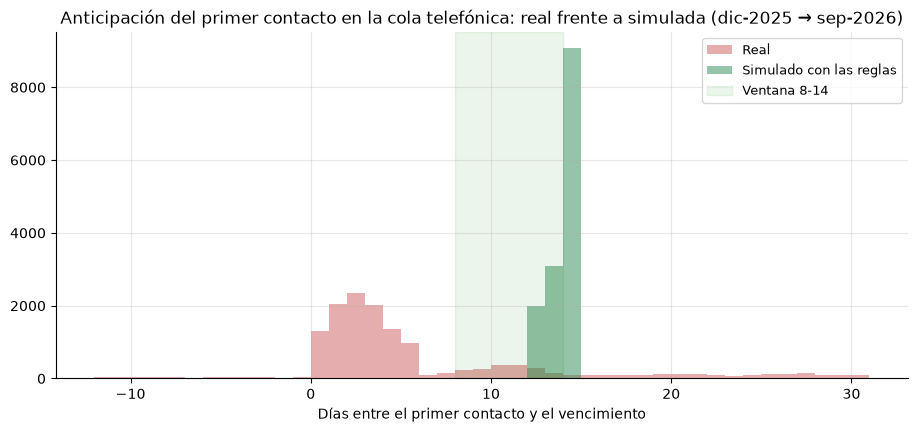

In [4]:
def simular_cola(polizas: pd.DataFrame, capacidad_diaria: int) -> pd.Series:
    # Devuelve la fecha simulada del primer contacto por póliza. Reglas: apertura a APERTURA_DIAS, fecha límite a LIMITE_DIAS,
    # orden por fecha límite y después por score; los seguimientos (llamadas históricas − 1) consumen capacidad un día cada uno.
    p = polizas.copy()
    p["apertura"] = p["Fecha de vencimiento"] - pd.Timedelta(days=APERTURA_DIAS)
    p["limite"] = p["Fecha de vencimiento"] - pd.Timedelta(days=LIMITE_DIAS)
    p["caduca"] = p["Fecha de vencimiento"] + pd.Timedelta(days=GRACIA_DIAS)
    p["score"] = p["potential_commission"] * p["Segmento"].map(TASA_VENTANA - TASA_TARDE).fillna(0)
    p = p.sort_values(["limite", "score"], ascending=[True, False])

    apertura = p["apertura"].to_numpy()
    caduca = p["caduca"].to_numpy()
    seguimientos = (p["calls_logged"].fillna(1).to_numpy() - 1).clip(min=0).astype(int)
    primer_contacto = np.full(len(p), np.datetime64("NaT", "ns"), dtype="datetime64[ns]")
    abierta = np.zeros(len(p), dtype=bool)
    pendientes = np.zeros(len(p), dtype=int)  # seguimientos que faltan por póliza abierta

    for dia in pd.bdate_range(p["apertura"].min(), p["caduca"].max()):
        hoy = np.datetime64(dia)
        # 1) seguimientos del día: una llamada por póliza abierta con seguimientos pendientes
        con_seguimiento = pendientes > 0
        usadas = int(con_seguimiento.sum())
        pendientes[con_seguimiento] -= 1
        # 2) primeros contactos con la capacidad que queda, en el orden de la cola (fecha límite, score)
        cupo = capacidad_diaria - usadas
        if cupo <= 0:
            continue
        elegibles = np.flatnonzero(~abierta & (apertura <= hoy) & (caduca >= hoy))[:cupo]
        abierta[elegibles] = True
        primer_contacto[elegibles] = hoy
        pendientes[elegibles] = seguimientos[elegibles]
    return pd.Series(primer_contacto, index=p.index, name="primer_contacto_simulado")


cola5 = r5[r5["canal"] == "Cola telefónica"].copy()
cola5["primer_contacto_simulado"] = simular_cola(cola5, CAPACIDAD_DIARIA)
cola5["lead_simulado"] = (cola5["Fecha de vencimiento"] - cola5["primer_contacto_simulado"]).dt.days
cola5["bucket_simulado"] = pd.cut(cola5["lead_simulado"], LEAD_BINS, labels=LEAD_LABELS)
sin_contacto = cola5["primer_contacto_simulado"].isna().sum()
print(f"Pólizas simuladas: {len(cola5):,}; sin cupo para el primer contacto antes de caducar: {sin_contacto}")

comparacion = pd.DataFrame(
    {
        "Real (5 gestores)": [
            cola5["lead_days"].median(),
            (cola5["lead_days"] <= 3).mean(),
            cola5["lead_bucket"].isin(VENTANA).mean(),
            (cola5["lead_days"] < 0).mean(),
        ],
        "Simulado con las reglas": [
            cola5["lead_simulado"].median(),
            (cola5["lead_simulado"] <= 3).mean(),
            cola5["bucket_simulado"].isin(VENTANA).mean(),
            (cola5["lead_simulado"] < 0).mean(),
        ],
    },
    index=[
        "Anticipación mediana (días)",
        "% primer contacto a ≤ 3 días",
        "% primer contacto en ventana 8-14",
        "% primer contacto después del vencimiento",
    ],
)
display(
    comparacion.style.format("{:.0f}", subset=pd.IndexSlice[["Anticipación mediana (días)"], :]).format(
        "{:.0%}", subset=pd.IndexSlice[comparacion.index[1:], :]
    )
)

fig, ax = plt.subplots()
bins = range(-12, 32)
ax.hist(cola5["lead_days"], bins=bins, alpha=0.5, label="Real", color="indianred")
ax.hist(
    cola5["lead_simulado"].dropna(), bins=bins, alpha=0.5, label="Simulado con las reglas", color="seagreen"
)
ax.axvspan(8, 14, color="green", alpha=0.08, label="Ventana 8-14")
ax.set_xlabel("Días entre el primer contacto y el vencimiento")
ax.set_title(
    "Anticipación del primer contacto en la cola telefónica: real frente a simulada (dic-2025 → sep-2026)"
)
ax.legend()
plt.show()

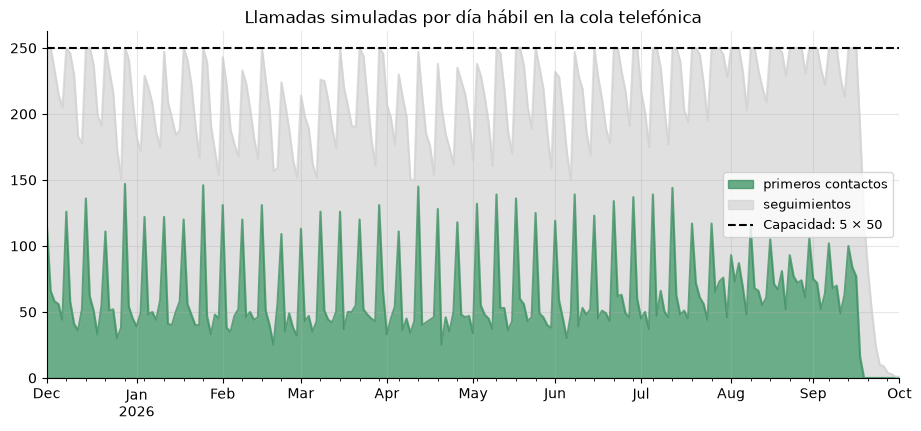

Uso medio de la capacidad: 83%; días al tope: 24%


In [5]:
# Uso de la capacidad día a día en la simulación: ¿alcanzan 5 gestores?
p = cola5.copy()
p["apertura"] = p["Fecha de vencimiento"] - pd.Timedelta(days=APERTURA_DIAS)
primeros = p["primer_contacto_simulado"].value_counts()
seguim = []
for fecha, grupo in p.dropna(subset=["primer_contacto_simulado"]).groupby("primer_contacto_simulado"):
    for k in range(1, int(grupo["calls_logged"].max())):
        seguim.append((fecha + pd.offsets.BDay(k), int((grupo["calls_logged"] - 1 >= k).sum())))
seguim = pd.DataFrame(seguim, columns=["fecha", "n"]).groupby("fecha")["n"].sum()
uso = pd.DataFrame({"primeros contactos": primeros, "seguimientos": seguim}).fillna(0).sort_index()
uso = uso.loc[str(STAFFING_CHANGE_DATE.date()) :]
uso["total"] = uso.sum(axis=1)
fig, ax = plt.subplots()
uso[["primeros contactos", "seguimientos"]].plot(
    kind="area", stacked=True, ax=ax, alpha=0.7, color=["seagreen", "lightgray"]
)
ax.axhline(CAPACIDAD_DIARIA, color="k", ls="--", label=f"Capacidad: {AGENTES} × {DAILY_CALL_TARGET}")
ax.set_title("Llamadas simuladas por día hábil en la cola telefónica")
ax.legend()
plt.show()
print(
    f"Uso medio de la capacidad: {uso['total'].mean() / CAPACIDAD_DIARIA:.0%}; días al tope: {(uso['total'] >= CAPACIDAD_DIARIA - 1).mean():.0%}"
)

- **Casi todos los primeros contactos caen en 8–14 días** y desaparecen los contactos después del vencimiento, sin llegar al tope de capacidad.
- Es optimista: usa los seguimientos reales de cada póliza, no descuenta feriados (~3.5 %) y supone que el canal automático no devuelve pólizas. El margen de capacidad cubre esa diferencia.

## 5. Impacto esperado
Cada póliza renueva a la tasa de su segmento en el tramo de su primer contacto (S2.15). Con el tramo real, el cálculo reproduce la comisión cobrada.

In [6]:
def esperado(df, col_bucket, tabla=None):
    # Comisión esperada: cada póliza renueva a la tasa de su segmento en el tramo indicado (tabla por defecto: 13 meses)
    tabla = tasa if tabla is None else tabla
    t = df.join(tabla.stack().rename("p"), on=["Segmento", col_bucket])
    return (t["p"].fillna(df["renewed"].mean()) * df["potential_commission"]).sum()


real_cobrado = cola5["earned_commission"].sum()
esp_real = esperado(cola5, "lead_bucket")
esp_sim = esperado(cola5, "bucket_simulado")
tasa_sim = (cola5.join(tasa.stack().rename("p"), on=["Segmento", "bucket_simulado"])["p"]).mean()
display(
    Markdown(f"""
| Cola telefónica, {meses_5} meses con 5 gestores | Valor |
|---|---|
| Comisión potencial | USD {cola5["potential_commission"].sum():,.0f} |
| Comisión realmente cobrada | USD {real_cobrado:,.0f} ({cola5["renewed"].mean():.1%} de renovación) |
| Esperada con los tramos reales (validación de la tabla; es dentro de muestra) | USD {esp_real:,.0f} ({esp_real / real_cobrado - 1:+.1%} frente a lo cobrado) |
| **Esperada con los tramos simulados** | **USD {esp_sim:,.0f}** (tasa esperada {tasa_sim:.1%}) |
| **Ganancia esperada** | **USD {esp_sim - esp_real:,.0f} en {meses_5} meses, ~USD {(esp_sim - esp_real) / meses_5:,.0f} al mes** |
| Referencia: pérdida estimada por contacto tardío en 01_eda §8 (estratificada, periodo de 5 gestores) | ~USD 45,000 al mes |
""")
)


| Cola telefónica, 10 meses con 5 gestores | Valor |
|---|---|
| Comisión potencial | USD 1,879,045 |
| Comisión realmente cobrada | USD 711,460 (37.7% de renovación) |
| Esperada con los tramos reales (validación de la tabla; es dentro de muestra) | USD 709,585 (-0.3% frente a lo cobrado) |
| **Esperada con los tramos simulados** | **USD 1,336,768** (tasa esperada 70.9%) |
| **Ganancia esperada** | **USD 627,183 en 10 meses, ~USD 62,718 al mes** |
| Referencia: pérdida estimada por contacto tardío en 01_eda §8 (estratificada, periodo de 5 gestores) | ~USD 45,000 al mes |


In [7]:
# Validación fuera de muestra y rango del impacto
cola7 = ren[(ren["active_agents"] == 7) & (ren["canal"] == "Cola telefónica")]
tasa7 = cola7.pivot_table(
    index="Segmento", columns="lead_bucket", values="renewed", aggfunc="mean", observed=True
)
esp_real_oot = esperado(
    cola5, "lead_bucket", tasa7
)  # tabla de 7 gestores aplicada a los tramos reales de 5 gestores
tasa_7g = cola7["renewed"].mean()
ganancia_piso = (tasa_7g - cola5["renewed"].mean()) * cola5["potential_commission"].sum()
ganancia_techo = esp_sim - esp_real
ganancia_meta = ganancia_techo * 0.70 / cola5["bucket_simulado"].isin(VENTANA).mean()  # meta: 70 % en ventana
print(
    f"Fuera de muestra: la tabla ajustada solo con 7 gestores, aplicada a los tramos reales del periodo de 5, da USD {esp_real_oot:,.0f} "
    f"frente a USD {real_cobrado:,.0f} cobrados ({esp_real_oot / real_cobrado - 1:+.1%}): la curva anticipación → renovación es estable entre periodos."
)
print(
    f"Tasa del tramo 8-14 en pago manual individual/pyme: {tasa.loc[['Individual', 'Pyme'], '8-14'].mean():.1%} (13 meses) "
    f"frente a {tasa7.loc[['Individual', 'Pyme'], '8-14'].mean():.1%} (solo 7 gestores) y "
    f"{cola5[(cola5['Gestor'] != 'G03') & (cola5['lead_bucket'] == '8-14')]['renewed'].mean():.1%} (5 gestores sin G03)."
)
display(
    Markdown(f"""
| Impacto mensual en la cola telefónica | USD al mes | Supuesto |
|---|---|---|
| **Piso** | **{ganancia_piso / meses_5:,.0f}** | volver a la tasa de la cola con 7 gestores ({tasa_7g:.1%} frente a {cola5["renewed"].mean():.1%} hoy), un estado observado |
| Meta del piloto | {ganancia_meta / meses_5:,.0f} | 70 % de primeros contactos en la ventana 8-14 (proporcional al techo) |
| **Techo** | **{ganancia_techo / meses_5:,.0f}** | simulación: {cola5["bucket_simulado"].isin(VENTANA).mean():.0%} de contactos en ventana a la tasa del tramo ({tasa_sim:.1%}) |
| Referencia | 39,000–45,000 | caída bruta de comisión 62 % → 51 % y pérdida estratificada de 01_eda §8 |
""")
)

Fuera de muestra: la tabla ajustada solo con 7 gestores, aplicada a los tramos reales del periodo de 5, da USD 714,136 frente a USD 711,460 cobrados (+0.4%): la curva anticipación → renovación es estable entre periodos.
Tasa del tramo 8-14 en pago manual individual/pyme: 71.4% (13 meses) frente a 68.4% (solo 7 gestores) y 67.5% (5 gestores sin G03).



| Impacto mensual en la cola telefónica | USD al mes | Supuesto |
|---|---|---|
| **Piso** | **28,615** | volver a la tasa de la cola con 7 gestores (52.9% frente a 37.7% hoy), un estado observado |
| Meta del piloto | 43,903 | 70 % de primeros contactos en la ventana 8-14 (proporcional al techo) |
| **Techo** | **62,718** | simulación: 100% de contactos en ventana a la tasa del tramo (70.9%) |
| Referencia | 39,000–45,000 | caída bruta de comisión 62 % → 51 % y pérdida estratificada de 01_eda §8 |


- La simulación es un **techo** (tasa global de 75 %), por eso el impacto se da como rango: **piso** = volver a la tasa con 7 gestores; **medio** = meta del piloto (70 % en ventana); **techo** = simulación.
- La validación fuera de muestra reproduce lo cobrado con error <1 %.
- Depende de que la relación anticipación → renovación sea causal: por eso se propone un piloto, no un despliegue.

## 6. Resumen visual para el Comité
Tramo del primer contacto hoy vs. con las reglas, y rango de comisión adicional. Se exportan a `outputs/figuras/`.

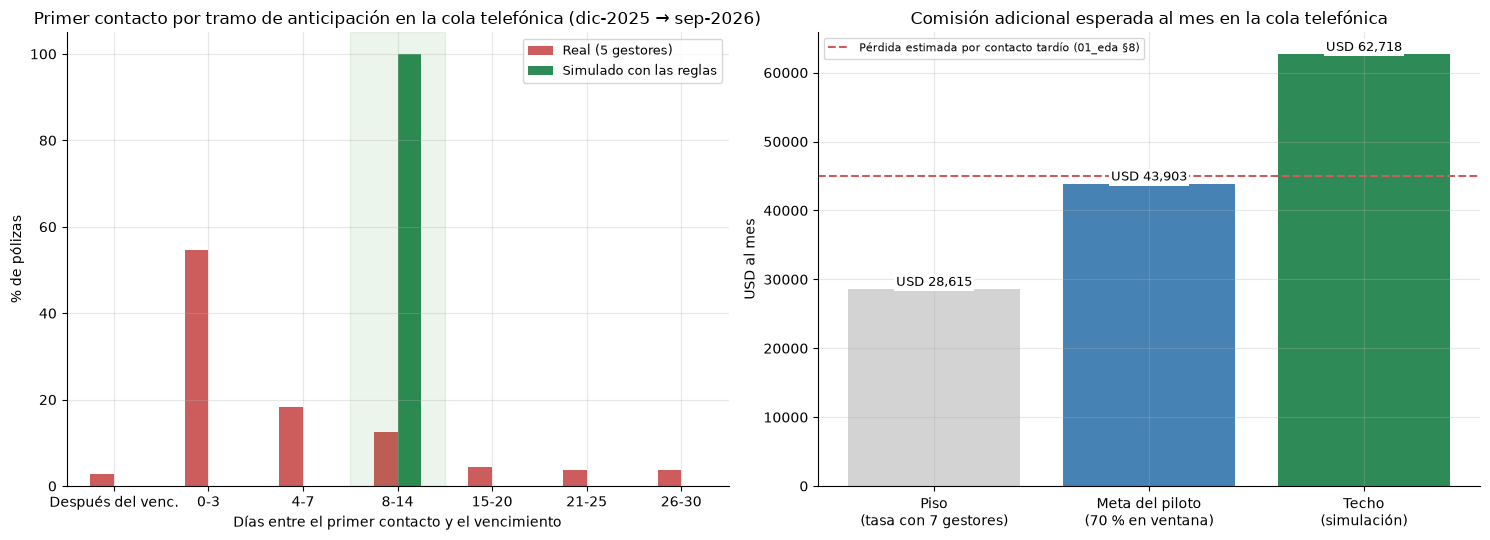

Exportado: outputs/figuras/caso2_resumen_comite_2025-12_a_2026-09.png


In [8]:
FIGURAS = OUTPUTS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

tramos = (
    pd.DataFrame(
        {
            "Real (5 gestores)": cola5["lead_bucket"].value_counts(normalize=True),
            "Simulado con las reglas": cola5["bucket_simulado"].value_counts(normalize=True),
        }
    )
    .reindex(LEAD_LABELS)
    .fillna(0)
    * 100
)
tramos.plot(kind="bar", ax=axes[0], color=["indianred", "seagreen"])
axes[0].axvspan(2.5, 3.5, color="green", alpha=0.08)
axes[0].set_title("Primer contacto por tramo de anticipación en la cola telefónica (dic-2025 → sep-2026)")
axes[0].set_ylabel("% de pólizas")
axes[0].set_xlabel("Días entre el primer contacto y el vencimiento")
axes[0].tick_params(axis="x", rotation=0)

impacto = (
    pd.Series(
        {
            "Piso\n(tasa con 7 gestores)": ganancia_piso,
            "Meta del piloto\n(70 % en ventana)": ganancia_meta,
            "Techo\n(simulación)": ganancia_techo,
        }
    )
    / meses_5
)
axes[1].bar(impacto.index, impacto.values, color=["lightgray", "steelblue", "seagreen"])
axes[1].axhline(45_000, color="indianred", ls="--", label="Pérdida estimada por contacto tardío (01_eda §8)")
for i, v in enumerate(impacto.values):
    axes[1].text(
        i,
        v,
        f"USD {v:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5),
    )
axes[1].set_title("Comisión adicional esperada al mes en la cola telefónica")
axes[1].set_ylabel("USD al mes")
axes[1].legend(fontsize=8)
plt.tight_layout()
ruta_fig = FIGURAS / f"caso2_resumen_comite_{STAFFING_CHANGE_DATE:%Y-%m}_a_{r5['expiry_month'].max()}.png"
fig.savefig(ruta_fig, dpi=150, bbox_inches="tight")
plt.show()
print("Exportado:", ruta_fig.relative_to(ROOT))

## 7. La cola del día
Lo que vería el gestor cada mañana, ordenado por fecha límite y valor (un día de ejemplo).

In [9]:
DIA_EJEMPLO = pd.Timestamp("2026-09-15")
cola_dia = cola5[
    (cola5["Fecha de vencimiento"] - pd.Timedelta(days=APERTURA_DIAS) <= DIA_EJEMPLO)
    & (cola5["primer_contacto_simulado"] >= DIA_EJEMPLO)
].copy()
cola_dia["Días al vencimiento"] = (cola_dia["Fecha de vencimiento"] - DIA_EJEMPLO).dt.days
cola_dia["Días para la fecha límite"] = cola_dia["Días al vencimiento"] - LIMITE_DIAS
cola_dia["Mejora esperada"] = cola_dia["Segmento"].map(TASA_VENTANA - TASA_TARDE)
cola_dia["Score (USD)"] = cola_dia["potential_commission"] * cola_dia["Mejora esperada"]
cola_dia = cola_dia.sort_values(["Días para la fecha límite", "Score (USD)"], ascending=[True, False])
cola_dia = cola_dia.rename(columns={"potential_commission": "Comisión potencial (USD)"})
cols = [  # lo que el gestor necesita para llamar y argumentar, en este orden
    "Póliza",
    "ID cliente",
    "Teléfono cliente",
    "Ramo",
    "Segmento",
    "Aseguradora",
    "Forma de pago",
    "Fecha de vencimiento",
    "Días al vencimiento",
    "Días para la fecha límite",
    "Prima anterior (USD)",
    "Prima de renovación (USD)",
    "% cambio de prima",
    "Comisión potencial (USD)",
    "Mejora esperada",
    "Score (USD)",
    "Número de intentos",
    "Gestor",
]
print(
    f"Cola del {DIA_EJEMPLO:%d-%b-%Y}: {len(cola_dia)} pólizas pendientes de primer contacto; se muestran las 15 primeras."
)
display(
    cola_dia[cols]
    .head(15)
    .style.format(
        {
            "Fecha de vencimiento": "{:%d-%b-%Y}",
            "Prima anterior (USD)": "{:,.0f}",
            "Prima de renovación (USD)": "{:,.0f}",
            "% cambio de prima": "{:+.1%}",
            "Comisión potencial (USD)": "{:,.0f}",
            "Mejora esperada": "{:+.0%}",
            "Score (USD)": "{:,.0f}",
        }
    )
    .hide(axis="index")
)

OUTPUTS.mkdir(parents=True, exist_ok=True)
ruta = OUTPUTS / f"cola_renovaciones_{DIA_EJEMPLO:%Y-%m-%d}.csv"
num = cola_dia[cols].select_dtypes("number").columns
cola_dia[cols].round({c: 2 for c in num}).to_csv(ruta, index=False, date_format="%Y-%m-%d")
print("Exportado:", ruta.relative_to(ROOT))

Cola del 15-Sep-2026: 116 pólizas pendientes de primer contacto; se muestran las 15 primeras.


Póliza,ID cliente,Teléfono cliente,Ramo,Segmento,Aseguradora,Forma de pago,Fecha de vencimiento,Días al vencimiento,Días para la fecha límite,Prima anterior (USD),Prima de renovación (USD),% cambio de prima,Comisión potencial (USD),Mejora esperada,Score (USD),Número de intentos,Gestor
CAP-DH-111156,CLI-001947,0182-8260,Daños / Hogar,Individual,Seguros del Lago,Manual,27-Sep-2026,12,4,302,315,+4.2%,54,+45%,24,6,G04
CAP-AU-106065,CLI-005913,0538-2950,Autos,Individual,Seguros del Lago,Manual,27-Sep-2026,12,4,331,347,+4.8%,52,+45%,23,2,G02
CAP-AU-108022,CLI-015640,0639-8370,Autos,Individual,Mutual Volcán,Manual,27-Sep-2026,12,4,310,343,+10.4%,51,+45%,23,9,G01
CAP-DH-113598,CLI-018536,0631-7557,Daños / Hogar,Individual,Aseguradora Pacífico Central,Manual,27-Sep-2026,12,4,263,262,-0.7%,47,+45%,21,2,G03
CAP-AU-123720,CLI-019893,0559-9618,Autos,Individual,Protecta Nicaragua,Manual,27-Sep-2026,12,4,277,283,+2.1%,42,+45%,19,5,G04
CAP-AU-114089,CLI-017254,0168-5083,Autos,Individual,Seguros del Lago,Manual,27-Sep-2026,12,4,273,300,+9.9%,42,+45%,19,2,G04
CAP-AU-109619,CLI-011815,0059-7270,Autos,Individual,Mutual Volcán,Manual,27-Sep-2026,12,4,242,257,+6.4%,36,+45%,16,1,G05
CAP-AU-116358,CLI-018103,0556-4983,Autos,Individual,Protecta Nicaragua,Manual,27-Sep-2026,12,4,215,230,+6.9%,34,+45%,15,1,G05
CAP-AU-123531,CLI-017019,0793-6405,Autos,Individual,Seguros del Lago,Manual,27-Sep-2026,12,4,216,232,+7.3%,32,+45%,14,7,G04
CAP-DH-102735,CLI-020561,0879-5418,Daños / Hogar,Individual,Aseguradora Pacífico Central,Manual,27-Sep-2026,12,4,173,176,+1.7%,30,+45%,13,4,G03


Exportado: outputs/cola_renovaciones_2026-09-15.csv


## 8. Medición y piloto

In [10]:
# Tamaño del piloto: ¿cuántos meses hacen falta para detectar una mejora de 5 puntos en la tasa de renovación de la cola telefónica?
p0 = cola5["renewed"].mean()
delta = 0.05
z_a, z_b = NormalDist().inv_cdf(0.975), NormalDist().inv_cdf(0.80)
n_brazo = 2 * (z_a + z_b) ** 2 * p0 * (1 - p0) / delta**2
polizas_gestor_mes = len(cola5) / meses_5 / AGENTES
print(
    f"Tasa base en la cola telefónica: {p0:.1%}. Para detectar +{delta:.0%} con 95 % de confianza y 80 % de potencia hacen falta ~{n_brazo:,.0f} pólizas por brazo. "
    f"Con ~{polizas_gestor_mes:,.0f} pólizas por gestor y mes, un piloto de 2 gestores frente a 3 necesita ~{n_brazo / (2 * polizas_gestor_mes):.1f} meses."
)

metricas = pd.DataFrame(
    [
        (
            "Anticipación mediana del primer contacto (cola telefónica)",
            f"{cola5['lead_days'].median():.0f} días",
            "≥ 10 días",
            "diaria, por gestor",
        ),
        (
            "% de primeros contactos en la ventana 8-14",
            f"{cola5['lead_bucket'].isin(VENTANA).mean():.0%}",
            "≥ 70 %",
            "semanal",
        ),
        (
            "% de primeros contactos después del vencimiento",
            f"{(cola5['lead_days'] < 0).mean():.1%}",
            "0 %",
            "semanal",
        ),
        (
            "Tasa de renovación, pago manual individual y pyme",
            f"{p0:.1%}",
            f"{tasa_7g:.0%} (piso: lo que tuvo con 7 gestores); {tasa_sim:.0%} es el techo de la simulación",
            "mensual, por brazo del piloto",
        ),
        (
            "Tasa de renovación del canal automático sin llamada",
            f"{r5.loc[r5['canal'].str.startswith('Canal'), 'renewed'].mean():.1%} (hoy, con llamada)",
            "sin caída",
            "mensual",
        ),
        (
            "Llamadas a teléfonos inválidos",
            f"{r5.loc[~r5['valid_phone'], 'calls_logged'].sum() / meses_5:,.0f} al mes",
            "0",
            "mensual",
        ),
        (
            "Comisión cobrada por gestor y mes",
            f"USD {r5['earned_commission'].sum() / meses_5 / AGENTES:,.0f}",
            "+10 %",
            "mensual",
        ),
    ],
    columns=["Métrica", "Hoy (5 gestores)", "Meta del piloto", "Frecuencia"],
)
metricas.style.hide(axis="index")

Tasa base en la cola telefónica: 37.7%. Para detectar +5% con 95 % de confianza y 80 % de potencia hacen falta ~1,475 pólizas por brazo. Con ~283 pólizas por gestor y mes, un piloto de 2 gestores frente a 3 necesita ~2.6 meses.


Métrica,Hoy (5 gestores),Meta del piloto,Frecuencia
Anticipación mediana del primer contacto (cola telefónica),3 días,≥ 10 días,"diaria, por gestor"
% de primeros contactos en la ventana 8-14,12%,≥ 70 %,semanal
% de primeros contactos después del vencimiento,2.7%,0 %,semanal
"Tasa de renovación, pago manual individual y pyme",37.7%,53% (piso: lo que tuvo con 7 gestores); 71% es el techo de la simulación,"mensual, por brazo del piloto"
Tasa de renovación del canal automático sin llamada,"91.8% (hoy, con llamada)",sin caída,mensual
Llamadas a teléfonos inválidos,179 al mes,0,mensual
Comisión cobrada por gestor y mes,"USD 42,099",+10 %,mensual


## 9. Prototipo: cómo funcionaría

Este notebook **es** el prototipo: enruta, prioriza y simula a partir del Excel, y la cola del día (§7) es lo que vería cada gestor por la mañana. Se vuelve a ejecutar con la base actualizada sin cambiar nada más que, si cambia la dotación, los parámetros de `00_limpieza`.

**Flujo diario:**

1. Cada póliza que vence en los próximos 14 días entra al sistema y se **enruta por canal** (§2): canal automático (domiciliadas, financiadas, flotas corporativas), corrección de datos (teléfono inválido) o cola telefónica (pago manual de individuales y pymes).
2. El canal automático envía el mensaje de renovación (WhatsApp o correo) 14 días antes del vencimiento; si no hay respuesta en 5 días, la póliza vuelve a la cola telefónica con prioridad.
3. La cola telefónica se **ordena por días para la fecha límite** (8 días antes del vencimiento) y, a igual fecha, por **comisión potencial × mejora esperada** del segmento (§3). Si un día no alcanza la capacidad, se posterga lo de menor valor, no lo que venció hace más tiempo.
4. Cada gestor recibe su lista con teléfono, vencimiento, prima anterior y nueva, cambio de prima, comisión, intentos previos y score (§7).
5. Los resultados de la bitácora **realimentan la tabla de tasas** por segmento y tramo de anticipación (§3) y las métricas de §8.

**Datos que usa:** la hoja *Renovaciones* (vencimiento, prima, comisión, forma de pago, segmento, teléfono, gestor), *Bitacora_Llamadas* (intentos, seguimientos, resultado) y *Equipo* (dotación y meta de llamadas, que fijan la capacidad). Nada que no exista ya. **Datos que pediría:** la regla operativa actual de apertura de la cola y por qué cambió en noviembre; si Flota corporativa se gestiona por otro proceso; cuándo llega la cotización de la aseguradora y su vigencia; qué clientes tienen correo o WhatsApp registrado; cómo se repartieron las carteras al salir G06 y G07; qué otras tareas hacen los gestores; y el calendario de feriados.

**Dónde entran la automatización y la IA.** La cola sale de reglas auditables, no de un modelo: el impacto está en operaciones (enrutar, abrir a 14 días, ordenar), y el canal automático es automatización, no IA. Con ~26,000 pólizas, resultado binario y variables ricas (ramo, aseguradora, cambio de prima, antigüedad, siniestros, historial), un modelo de propensión a renovar sí está justificado por el tamaño de los datos; pero lo que importa para priorizar no es quién renueva sino el *uplift*, a quién le cambia el resultado llamarlo a tiempo, y eso solo se estima bien con los datos aleatorizados del piloto. Por eso es segunda etapa. La IA apoya en:

- (a) **Un modelo de propensión / uplift por póliza**, calibrado con los resultados del piloto, que afine la «mejora esperada» más allá del segmento.
- (b) **Redactar y enviar los mensajes del canal automático** y leer la respuesta del cliente: si pide hablar, la póliza vuelve a la cola con prioridad.
- (c) **Un resumen de la última interacción** antes de cada llamada de seguimiento.
- (d) **Clasificar los motivos de no renovación** en texto libre.

**Cómo se mediría:** con la tabla de §8, línea base el periodo de 5 gestores. Anticipación mediana del primer contacto (diaria, por gestor); % de primeros contactos en la ventana 8-14 y % después del vencimiento (semanal); tasa de renovación de la cola telefónica por brazo del piloto (mensual); tasa del canal automático sin llamada, que no debe caer; llamadas a teléfonos inválidos, que deben ser cero; y comisión cobrada por gestor y mes. El piloto A/B de 2 frente a 3 gestores necesita ~1,475 pólizas por brazo (~3 meses) para detectar una mejora de 5 puntos con 95 % de confianza.

In [11]:
display(
    Markdown(f"""
## 10. Respuesta al Comité de Capesa

### Diagnóstico

Desde diciembre de 2025 el primer contacto ocurre a 3 días del vencimiento en lugar de 16, el 57 % de las pólizas se contacta a 3 días o menos (10 % con 7 gestores) y la tasa de renovación cayó de 62.0 % a 50.6 %, unos USD 39,000 al mes de comisión. Lo que muestran los datos:

- **Hay dos causas, no una.** Al pasar de 7 a 5 gestores el equipo perdió un 16 % de su caudal: hacía ~310 llamadas por día hábil (44-45 por gestor) y hace ~260 (52 por gestor; el 59 % de los gestor-día supera la meta de 50). Los 5 están saturados, no ociosos. Y, además, cambió la regla de apertura de la cola: en octubre se había abierto el 58 % de los expedientes de noviembre; en noviembre, aún con 7 gestores y al 61 % de su capacidad, solo se abrió el 16 % de los de diciembre. La apertura temprana se detuvo antes de que saliera nadie.
- **El déficit de capacidad es pequeño (~6 %):** con 3.0 llamadas por póliza la carga supera la capacidad de 5 × 50 llamadas por un 6 % en promedio. Contratar no es la primera palanca.
- **La ventana que renueva es 8-14 días antes del vencimiento, no «lo antes posible»:** ahí la tasa es 74 %, frente a 42 % a 3 días o menos y 60 % a más de 20 días. Se sostiene en todos los ramos y periodos, y es más fuerte donde importa: en pago manual de individuales y pymes, 70 % frente a 26 %.
- **Nadie prioriza por valor.** El 51 % de las pólizas genera el 80 % de la comisión, pero la anticipación no depende de la prima: todas se tratan igual, por orden de vencimiento.
- **Una cuarta parte de la cartera casi no necesita llamada.** Domiciliadas (95 %), financiadas (91 %) y flotas corporativas (87 %) renuevan igual sin importar cuándo se las llame; son el 24 % de las pólizas, el 45 % de la comisión y consumen ~930 llamadas al mes. Y 522 pólizas con teléfono inválido consumieron 2,401 llamadas sin lograr ni un contacto.
- **G03 demuestra que se puede:** con la misma carga mantiene 10 días de anticipación y renueva 65 % frente a 47 % del resto; el 75 % de esa ventaja se explica por la anticipación y la mezcla de su cartera, no por un método aparte.

### Propuesta: tres reglas sin contratar

1. **Enrutar por canal antes de llamar.** Domiciliadas, financiadas y flotas corporativas reciben un mensaje 14 días antes del vencimiento y solo entran a la cola si no responden; las pólizas con teléfono inválido van a corrección de datos. Saca de la cola ~{liberadas:,.0f} llamadas al mes ({liberadas / (t5["llamadas_historicas"].sum() / meses_5):.0%} del total): tres veces el déficit de capacidad y la mayor parte del caudal perdido al pasar de 7 a 5 gestores.
2. **Abrir cada expediente 14 días antes del vencimiento, no a 3.** Es el cambio que revierte el escalón de diciembre.
3. **Ordenar la cola por fecha límite y valor.** Primero las pólizas que están por salir de la ventana (8 días antes del vencimiento es la fecha límite); a igual fecha, por comisión potencial × mejora esperada del segmento.

### Impacto esperado

En la simulación sobre los {meses_5} meses con 5 gestores, día hábil por día hábil y con los mismos seguimientos que cada póliza consumió en la realidad, el {cola5["bucket_simulado"].isin(VENTANA).mean():.0%} de los primeros contactos de la cola telefónica cae en la ventana de 8-14 días (hoy {cola5["lead_bucket"].isin(VENTANA).mean():.0%}), sin contactos después del vencimiento, usando el {uso["total"].mean() / CAPACIDAD_DIARIA:.0%} de la capacidad. En comisión, el impacto se reporta como rango porque la cifra de la simulación es un techo:

| Escenario | USD al mes | Supuesto |
|---|---|---|
| Piso | ~{ganancia_piso / meses_5:,.0f} | la cola telefónica vuelve a la tasa que tuvo con 7 gestores ({tasa_7g:.0%} frente a {cola5["renewed"].mean():.0%} hoy): un estado observado |
| Meta del piloto | ~{ganancia_meta / meses_5:,.0f} | 70 % de primeros contactos en la ventana 8-14; del orden de la pérdida estimada por contacto tardío (USD 45,000) |
| Techo | ~{ganancia_techo / meses_5:,.0f} | {cola5["bucket_simulado"].isin(VENTANA).mean():.0%} de contactos en ventana a la tasa del tramo ({tasa_sim:.0%}), por encima de lo que el equipo ha logrado nunca |

La curva anticipación → renovación es estable entre periodos (la tabla ajustada solo con los 7 gestores reproduce lo cobrado con 5 con un error del {abs(esp_real_oot / real_cobrado - 1):.1%}), pero sigue siendo una expectativa condicionada a que sea causal: puede haber sesgo de selección si los gestores dejaban para el final a los clientes difíciles. Por eso la propuesta se pone en marcha como piloto medido, no como despliegue.

### Puesta en marcha

1. **Semanas 1-2, datos:** corregir los 522 teléfonos inválidos (o marcar esas pólizas para otro canal), confirmar qué clientes tienen WhatsApp o correo registrado y pedir al área la regla operativa actual de apertura de la cola y por qué cambió en noviembre.
2. **Semana 3, canal automático:** mensaje de renovación a domiciliadas, financiadas y flotas corporativas 14 días antes del vencimiento; llamada solo si no hay respuesta en 5 días. Vigilar que su tasa no caiga.
3. **Meses 1-3, piloto A/B por gestor:** dos gestores trabajan con la cola priorizada (apertura a 14 días, orden por fecha límite y score) y tres siguen como hoy, con carteras asignadas al azar dentro de cada ramo. Para detectar 5 puntos de mejora con 95 % de confianza hacen falta ~{n_brazo:,.0f} pólizas por brazo: ~{max(2, round(n_brazo / (2 * polizas_gestor_mes))):.0f} meses.
4. **Mes 4, decisión:** si la cola priorizada renueva más, se extiende a los cinco gestores; si no, la curva no era causal y la palanca pasa a ser el seguimiento de las pólizas que quedan en «Cotización enviada» o la contratación.

*Los dieciséis supuestos (S2.1–S2.16) se explican en las celdas de los notebooks donde se aplican; los de más peso son S2.8 (anticipación medida con el primer intento), S2.7 (dos periodos por la salida de G06 y G07), S2.10-S2.11 (capacidad) y S2.14-S2.16 (canal automático y simulación). Los datos muestran señales de ser sintéticos (misma tasa de contacto a toda hora, llamadas en feriados, mediana exacta de 3 días todos los meses), lo que limita las conclusiones sobre contactabilidad y seguimiento.*
""")
)


## 10. Respuesta al Comité de Capesa

### Diagnóstico

Desde diciembre de 2025 el primer contacto ocurre a 3 días del vencimiento en lugar de 16, el 57 % de las pólizas se contacta a 3 días o menos (10 % con 7 gestores) y la tasa de renovación cayó de 62.0 % a 50.6 %, unos USD 39,000 al mes de comisión. Lo que muestran los datos:

- **Hay dos causas, no una.** Al pasar de 7 a 5 gestores el equipo perdió un 16 % de su caudal: hacía ~310 llamadas por día hábil (44-45 por gestor) y hace ~260 (52 por gestor; el 59 % de los gestor-día supera la meta de 50). Los 5 están saturados, no ociosos. Y, además, cambió la regla de apertura de la cola: en octubre se había abierto el 58 % de los expedientes de noviembre; en noviembre, aún con 7 gestores y al 61 % de su capacidad, solo se abrió el 16 % de los de diciembre. La apertura temprana se detuvo antes de que saliera nadie.
- **El déficit de capacidad es pequeño (~6 %):** con 3.0 llamadas por póliza la carga supera la capacidad de 5 × 50 llamadas por un 6 % en promedio. Contratar no es la primera palanca.
- **La ventana que renueva es 8-14 días antes del vencimiento, no «lo antes posible»:** ahí la tasa es 74 %, frente a 42 % a 3 días o menos y 60 % a más de 20 días. Se sostiene en todos los ramos y periodos, y es más fuerte donde importa: en pago manual de individuales y pymes, 70 % frente a 26 %.
- **Nadie prioriza por valor.** El 51 % de las pólizas genera el 80 % de la comisión, pero la anticipación no depende de la prima: todas se tratan igual, por orden de vencimiento.
- **Una cuarta parte de la cartera casi no necesita llamada.** Domiciliadas (95 %), financiadas (91 %) y flotas corporativas (87 %) renuevan igual sin importar cuándo se las llame; son el 24 % de las pólizas, el 45 % de la comisión y consumen ~930 llamadas al mes. Y 522 pólizas con teléfono inválido consumieron 2,401 llamadas sin lograr ni un contacto.
- **G03 demuestra que se puede:** con la misma carga mantiene 10 días de anticipación y renueva 65 % frente a 47 % del resto; el 75 % de esa ventaja se explica por la anticipación y la mezcla de su cartera, no por un método aparte.

### Propuesta: tres reglas sin contratar

1. **Enrutar por canal antes de llamar.** Domiciliadas, financiadas y flotas corporativas reciben un mensaje 14 días antes del vencimiento y solo entran a la cola si no responden; las pólizas con teléfono inválido van a corrección de datos. Saca de la cola ~1,109 llamadas al mes (19% del total): tres veces el déficit de capacidad y la mayor parte del caudal perdido al pasar de 7 a 5 gestores.
2. **Abrir cada expediente 14 días antes del vencimiento, no a 3.** Es el cambio que revierte el escalón de diciembre.
3. **Ordenar la cola por fecha límite y valor.** Primero las pólizas que están por salir de la ventana (8 días antes del vencimiento es la fecha límite); a igual fecha, por comisión potencial × mejora esperada del segmento.

### Impacto esperado

En la simulación sobre los 10 meses con 5 gestores, día hábil por día hábil y con los mismos seguimientos que cada póliza consumió en la realidad, el 100% de los primeros contactos de la cola telefónica cae en la ventana de 8-14 días (hoy 12%), sin contactos después del vencimiento, usando el 83% de la capacidad. En comisión, el impacto se reporta como rango porque la cifra de la simulación es un techo:

| Escenario | USD al mes | Supuesto |
|---|---|---|
| Piso | ~28,615 | la cola telefónica vuelve a la tasa que tuvo con 7 gestores (53% frente a 38% hoy): un estado observado |
| Meta del piloto | ~43,903 | 70 % de primeros contactos en la ventana 8-14; del orden de la pérdida estimada por contacto tardío (USD 45,000) |
| Techo | ~62,718 | 100% de contactos en ventana a la tasa del tramo (71%), por encima de lo que el equipo ha logrado nunca |

La curva anticipación → renovación es estable entre periodos (la tabla ajustada solo con los 7 gestores reproduce lo cobrado con 5 con un error del 0.4%), pero sigue siendo una expectativa condicionada a que sea causal: puede haber sesgo de selección si los gestores dejaban para el final a los clientes difíciles. Por eso la propuesta se pone en marcha como piloto medido, no como despliegue.

### Puesta en marcha

1. **Semanas 1-2, datos:** corregir los 522 teléfonos inválidos (o marcar esas pólizas para otro canal), confirmar qué clientes tienen WhatsApp o correo registrado y pedir al área la regla operativa actual de apertura de la cola y por qué cambió en noviembre.
2. **Semana 3, canal automático:** mensaje de renovación a domiciliadas, financiadas y flotas corporativas 14 días antes del vencimiento; llamada solo si no hay respuesta en 5 días. Vigilar que su tasa no caiga.
3. **Meses 1-3, piloto A/B por gestor:** dos gestores trabajan con la cola priorizada (apertura a 14 días, orden por fecha límite y score) y tres siguen como hoy, con carteras asignadas al azar dentro de cada ramo. Para detectar 5 puntos de mejora con 95 % de confianza hacen falta ~1,475 pólizas por brazo: ~3 meses.
4. **Mes 4, decisión:** si la cola priorizada renueva más, se extiende a los cinco gestores; si no, la curva no era causal y la palanca pasa a ser el seguimiento de las pólizas que quedan en «Cotización enviada» o la contratación.

*Los dieciséis supuestos (S2.1–S2.16) se explican en las celdas de los notebooks donde se aplican; los de más peso son S2.8 (anticipación medida con el primer intento), S2.7 (dos periodos por la salida de G06 y G07), S2.10-S2.11 (capacidad) y S2.14-S2.16 (canal automático y simulación). Los datos muestran señales de ser sintéticos (misma tasa de contacto a toda hora, llamadas en feriados, mediana exacta de 3 días todos los meses), lo que limita las conclusiones sobre contactabilidad y seguimiento.*
